In [25]:
#import libs
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [26]:
#loadind dataset
df = pd.read_csv("combined_file.csv")
print(df.head())

   Name     Date       Open       High        Low      Close  Adj Close  \
0  AMZN  7/30/18  91.366501  91.474998  88.301003  88.960999  88.960999   
1  AMZN  7/31/18  89.324501  90.091499  86.966003  88.872002  88.872002   
2  AMZN   8/1/18  89.199997  89.921997  88.801003  89.858498  89.858498   
3  AMZN   8/2/18  89.438499  91.828003  89.300003  91.716499  91.716499   
4  AMZN   8/3/18  91.887001  92.050003  91.074997  91.164497  91.164497   

      Volume  
0  131246000  
1  114774000  
2   83062000  
3   87094000  
4   69210000  


In [3]:
#exploring dataset
print(df.info())
print(df.describe())
print(df.isnull().sum()) #checking for missing values

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8812 entries, 0 to 8811
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Name       8812 non-null   object
 1   Date       8812 non-null   object
 2   Open       8812 non-null   object
 3   High       8812 non-null   object
 4   Low        8812 non-null   object
 5   Close      8812 non-null   object
 6   Adj Close  8812 non-null   object
 7   Volume     8812 non-null   object
dtypes: object(8)
memory usage: 550.9+ KB
None
        Name     Date  Open  High   Low  Close  Adj Close  Volume
count   8812     8812  8812  8812  8812   8812       8812    8812
unique     8     1259  8057  8107  8117   8245       8614    8718
top     AMZN  7/28/23  Open  High   Low  Close  Adj Close  Volume
freq    1258        7     6     6     6      6          6       6
Name         0
Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: 

In [4]:
#data preprocessing
df = df[df["Date"] != "Date"] #remove duplicated header rows
df["Date"] = pd.to_datetime(df["Date"], format="%m/%d/%y") #convert date column to datetime
df = df.sort_values(["Name", "Date"]) #sort values by company and date
df = df.reset_index(drop=True) #reset index
print(df["Name"].unique()) #checking for unique companies

numeric_columns = [  
    "Open",
    "High",
    "Low",
    "Close",
    "Adj Close",
    "Volume"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce") #convert all possible object columns into numerical

['AAPL' 'AMZN' 'GOOG' 'META' 'MSFT' 'NFLX' 'NVDA']


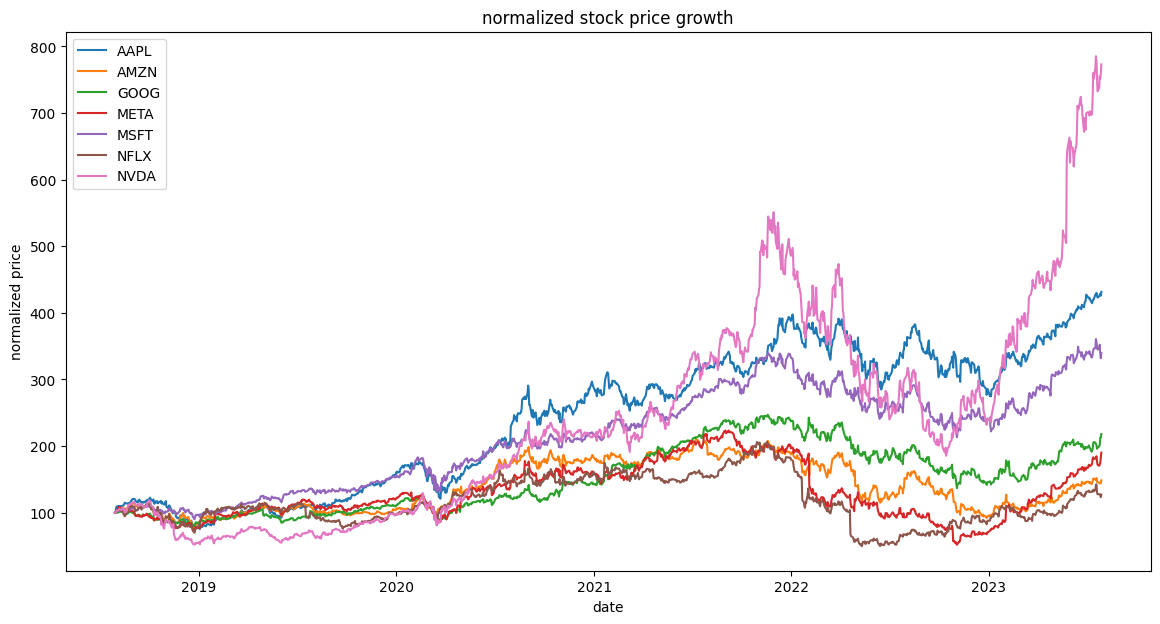

total growth percentage
Name
NVDA    673.045167
AAPL    331.599629
MSFT    239.528732
GOOG    118.095652
META     90.272428
AMZN     48.615695
NFLX     27.113688
dtype: float64


In [14]:
#question 1
#which company showed the highest stock growth in 2018-2023?
pivot_close = df.pivot(index="Date", columns="Name", values="Adj Close") #create pivot table for Adj close
normalized_prices = pivot_close / pivot_close.iloc[0] * 100 #normalizing prices to see the real differences between companies growth

plt.figure(figsize=(14, 7))

for company in normalized_prices.columns:
    plt.plot( #plot of normalized prices
        normalized_prices.index,
        normalized_prices[company],
        label=company
    )

plt.title("normalized stock price growth")
plt.xlabel("date")
plt.ylabel("normalized price")
plt.legend()
plt.savefig('plot_1.png', bbox_inches='tight')
plt.show()

#calculate total growth percentage
growth = ((pivot_close.iloc[-1] - pivot_close.iloc[0]) / pivot_close.iloc[0]) * 100
growth = growth.sort_values(ascending=False)
print("total growth percentage")
print(growth)

In [19]:
#conclusion
print("\nas we can see, nvidia showed the highest stock growth during this period")
print("netflix and amazon had much weaker performance compared to others")
print("most companies experienced long term upward trends despite short term declines")


as we can see, nvidia showed the highest stock growth during this period
netflix and amazon had much weaker performance compared to others
most companies experienced long term upward trends despite short term declines


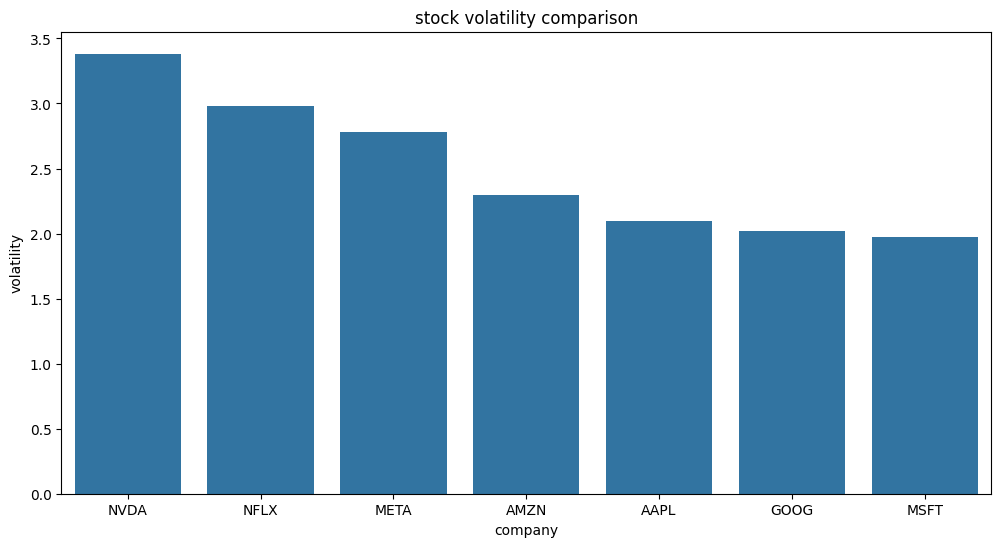

In [15]:
#question 2
#which company had the highest volatility?
daily_returns = pivot_close.pct_change() #calculate daily returns with .pct_change
volatility = daily_returns.std() * 100 #standard deviation of returns in percents
volatility = volatility.sort_values(ascending=False) 
plt.figure(figsize=(12, 6)) #volatility plot

sns.barplot(
    x=volatility.index,
    y=volatility.values
)

plt.title("stock volatility comparison")
plt.xlabel("company")
plt.ylabel("volatility")
plt.savefig('plot_2.png', bbox_inches='tight')
plt.show()

In [9]:
#display volatility table
volatility_table = pd.DataFrame({
    "company": volatility.index,
    "volatility": volatility.values
})
print(volatility_table) #shows every day's average stocks changes in percents

#conclusion
print("nvidia and netflix were the most volatile stocks")
print("apple, google and microsoft are the most stable, compared to others")

  company  volatility
0    NVDA    3.382384
1    NFLX    2.983595
2    META    2.782454
3    AMZN    2.297743
4    AAPL    2.098466
5    GOOG    2.020737
6    MSFT    1.971575
nvidia and netflix were the most volatile stocks
apple, google and microsoft are the most stable, compared to others


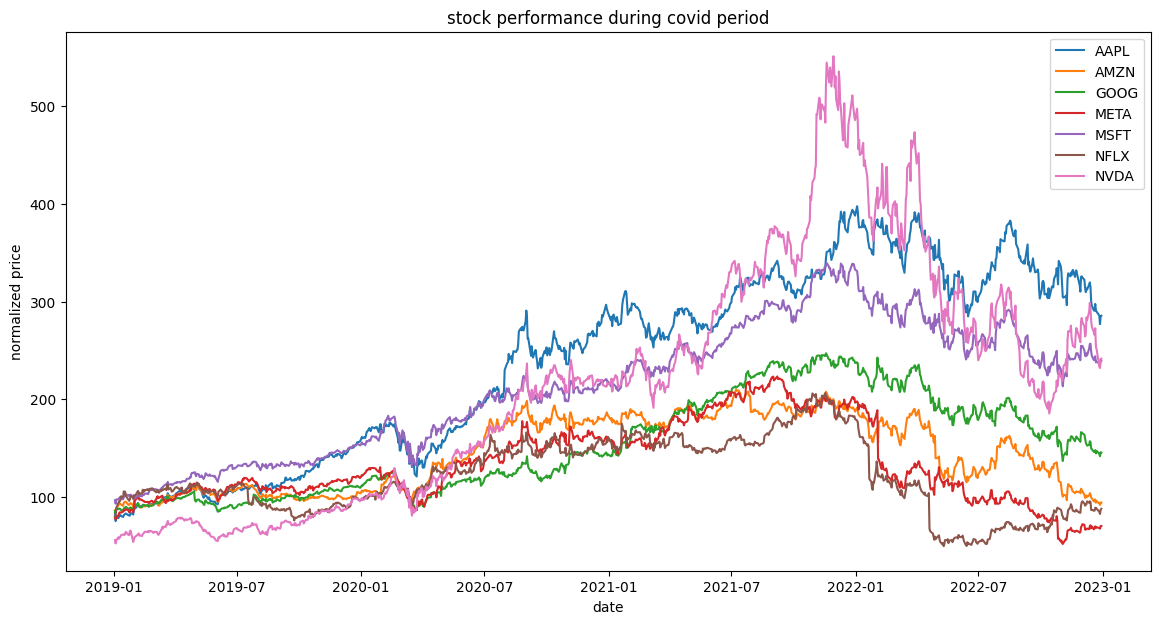

In [24]:
#question 3
#how did crisis of covid-19 affected stocks?
covid_data = normalized_prices.loc["2019-01-01":"2022-12-31"] #covid period

plt.figure(figsize=(14, 7)) #plot covid period

for company in covid_data.columns:
    plt.plot(
        covid_data.index,
        covid_data[company],
        label=company
    )

plt.title("stock performance during covid period")
plt.xlabel("date")
plt.ylabel("normalized price")
plt.legend()
plt.savefig('plot_3.png', bbox_inches='tight')
plt.show()

In [23]:
#conclusion
print("most stocks dropped sharply at the beginning of 2020")
print("nvidia, apple and microsoft recovered very quickly after the market crashed and showed the best results during the covid period")

most stocks dropped sharply at the beginning of 2020
nvidia, apple and microsoft recovered very quickly after the market crashed and showed the best results during the covid period


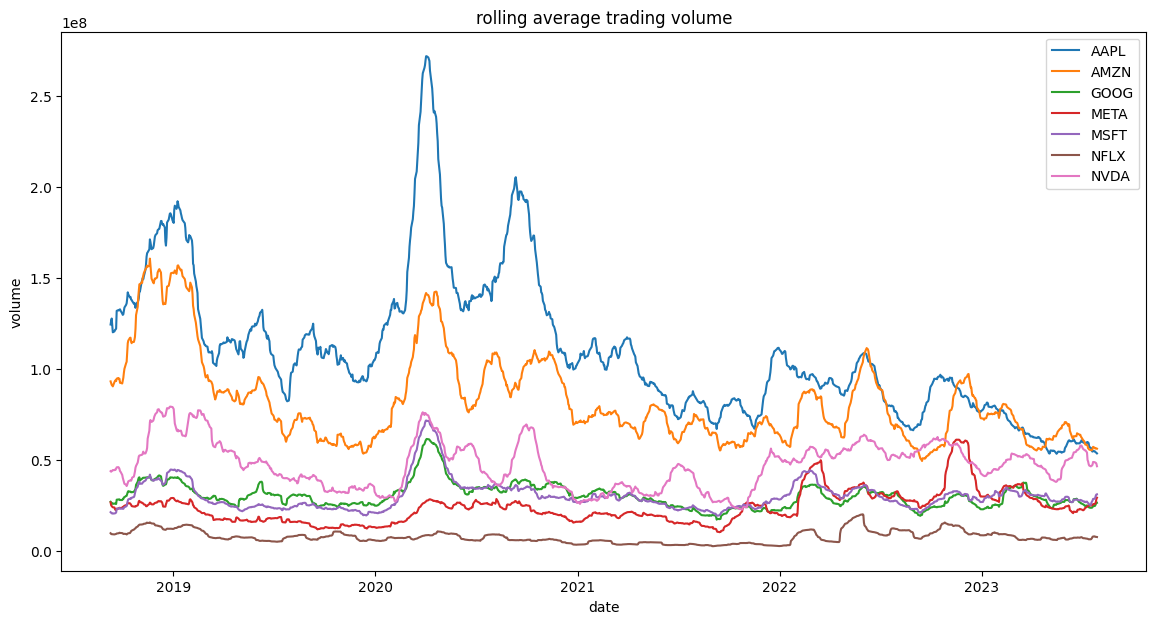

In [17]:
#question 4
#how did trading volume change during major market events?
pivot_volume = df.pivot(index="Date", columns="Name", values="Volume") #create pivot table for volume
rolling_volume = pivot_volume.rolling(window=30).mean() #calculate average volume in last 30 days for each day

#plot rolling volume
plt.figure(figsize=(14, 7))

for company in rolling_volume.columns:
    plt.plot(
        rolling_volume.index,
        rolling_volume[company],
        label=company
    )

plt.title("rolling average trading volume")
plt.xlabel("date")
plt.ylabel("volume")
plt.legend()
plt.savefig('plot_4.png', bbox_inches='tight')
plt.show()

In [13]:
#conclusion
print("trading volume increased significantly during periods of market uncertainty")
print("covid period caused major spikes in trading activity")
print("apple and amazon related market trends and attracted highest trading volumes")

trading volume increased significantly during periods of market uncertainty
covid period caused major spikes in trading activity
apple and amazon related market trends and attracted highest trading volumes
